# 03 — Exploração do Dataset ABIDE I — TEA

Este notebook realiza a exploração inicial dos dados do ABIDE I
utilizados no estudo de classificação de Transtorno do Espectro Autista.

Serão analisados:

- informações fenotípicas;
- distribuição dos grupos;
- distribuição por site;
- características das séries temporais;
- número de ROIs;
- número de timepoints;
- visualização das séries temporais.

**Objetivo:** Explorar fenótipos (diagnóstico, site, idade, sexo) e visualizar neuroimagem e séries temporais.

**Entradas:** `Data/raw/phenotypic_abide.csv`, `Data/roi_timeseries/roi_timeseries_abide.pkl` (notebook 02); atlas CC200 e exemplos de imagem são baixados somente se faltarem.

**Processamento:** Tabelas e gráficos descritivos; checagem de confundimento diagnóstico × site.

**Saídas:** `Figures/03_*.png`, `Docs/03_resumo_exploracao.txt`, `Data/raw/cc200_roi_atlas.nii.gz`.

In [1]:
# ------------------------------------------------------------
# Configuração do projeto (execução local — VS Code)
# Garante que a raiz do projeto esteja no sys.path, funcionando tanto se o
# diretório de trabalho do kernel for notebooks/ quanto a raiz do projeto.
# ------------------------------------------------------------
import sys
from pathlib import Path

_raiz = Path.cwd().resolve()
for _cand in (_raiz, *_raiz.parents):
    if (_cand / 'src' / 'config.py').exists():
        _raiz = _cand
        break
else:
    raise RuntimeError(
        'Não foi possível localizar a pasta src/config.py a partir de '
        f'{Path.cwd()}. Abra a pasta TCC_TEA_TDAH/ no VS Code.'
    )
if str(_raiz) not in sys.path:
    sys.path.insert(0, str(_raiz))

import os
import random
import numpy as np

from src.config import BASE_DIR, PATHS, SEED, criar_pastas
from src.utils import exigir_arquivo

criar_pastas()

random.seed(SEED)
np.random.seed(SEED)

print('Projeto (BASE_DIR) =', BASE_DIR)

Projeto (BASE_DIR) = C:\Users\Maria Eduarda\Downloads\TCC_TEA_TDAH


In [2]:
# ============================================================
# CARREGAMENTO DOS DADOS FENOTÍPICOS
# ============================================================

exigir_arquivo(
    PATHS['raw'] / 'phenotypic_abide.csv',
    '02_Download_ABIDE.ipynb'
)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

phenotypic = pd.read_csv(
    PATHS['raw'] / 'phenotypic_abide.csv'
)

# ------------------------------------------------------------
# Padronizar identificador do participante
# ------------------------------------------------------------

phenotypic['SUB_ID'] = (
    phenotypic['SUB_ID']
    .astype(str)
)

# ------------------------------------------------------------
# Conferência
# ------------------------------------------------------------

print(
    'Total de registros:',
    len(phenotypic)
)

print(
    'SUB_ID únicos:',
    phenotypic['SUB_ID'].nunique()
)

print()
print(
    'Distribuição por grupo diagnóstico:'
)

print(
    phenotypic['DX_GROUP']
    .value_counts()
)

print()
print(
    'Distribuição por site:'
)

print(
    phenotypic['SITE_ID']
    .value_counts()
)

Total de registros: 871
SUB_ID únicos: 871

Distribuição por grupo diagnóstico:
DX_GROUP
2    468
1    403
Name: count, dtype: int64

Distribuição por site:
SITE_ID
NYU         172
UM_1         86
USM          67
UCLA_1       64
PITT         50
MAX_MUN      46
TRINITY      44
YALE         41
UM_2         34
KKI          33
OLIN         28
LEUVEN_1     28
LEUVEN_2     28
SDSU         27
SBL          26
OHSU         25
STANFORD     25
UCLA_2       21
CALTECH      15
CMU          11
Name: count, dtype: int64


## Diagnóstico x Site — checagem de confundimento


DX_GROUP  TEA  Controle
SITE_ID                
CALTECH     5        10
CMU         6         5
KKI        12        21
LEUVEN_1   14        14
LEUVEN_2   12        16
MAX_MUN    19        27
NYU        74        98
OHSU       12        13
OLIN       14        14
PITT       24        26
SBL        12        14
SDSU        8        19
STANFORD   12        13
TRINITY    19        25
UCLA_1     37        27
UCLA_2     11        10
UM_1       34        52
UM_2       13        21
USM        43        24
YALE       22        19


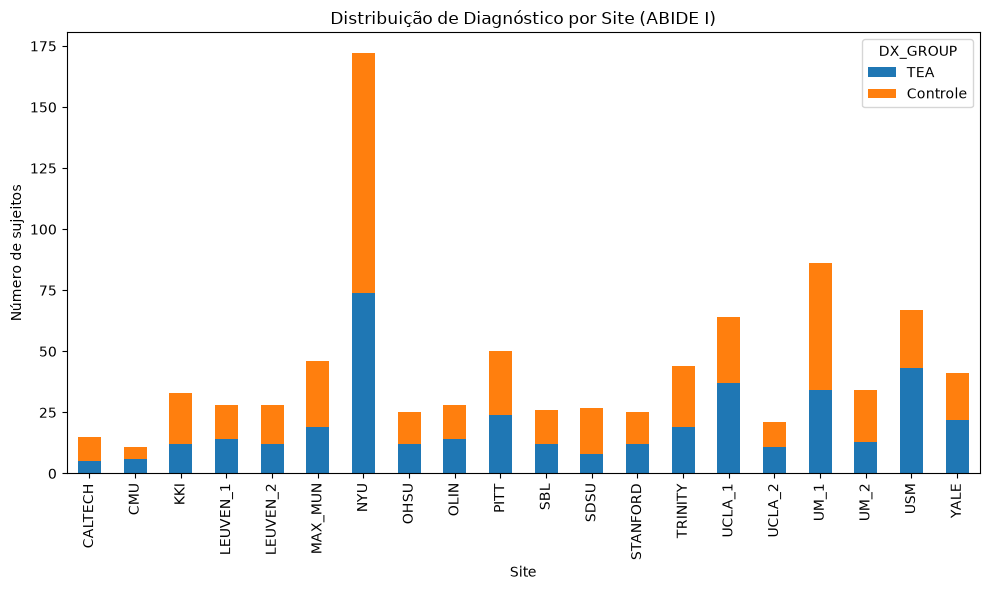

In [3]:
tabela_cruzada = pd.crosstab(
    phenotypic['SITE_ID'],
    phenotypic['DX_GROUP']
)



tabela_cruzada = tabela_cruzada.rename(
    columns={
        1: 'TEA',
        2: 'Controle'
    }
)

print(
    tabela_cruzada
)



fig, ax = plt.subplots(
    figsize=(10, 6)
)

tabela_cruzada.plot(
    kind='bar',
    stacked=True,
    ax=ax
)

ax.set_title(
    'Distribuição de Diagnóstico por Site (ABIDE I)'
)

ax.set_xlabel(
    'Site'
)

ax.set_ylabel(
    'Número de sujeitos'
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        PATHS['figures'],
        '03_distribuicao_diagnostico_site.png'
    ),
    dpi=150
)

plt.show()

## Distribuição de idade e sexo por grupo diagnóstico

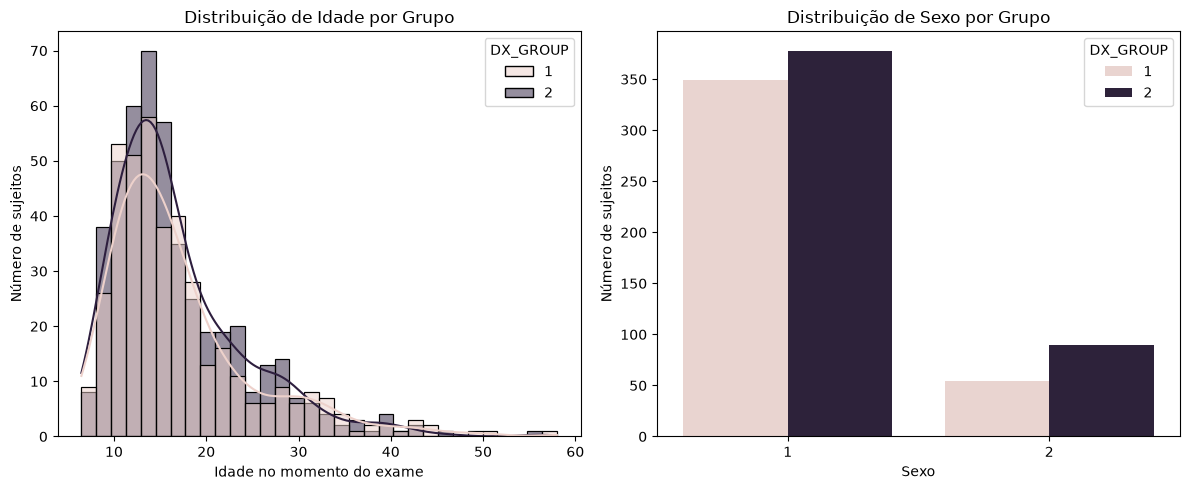

In [4]:
# ============================================================
# DISTRIBUIÇÃO DE IDADE E SEXO
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5)
)

# ------------------------------------------------------------
# Idade
# ------------------------------------------------------------

sns.histplot(
    data=phenotypic,
    x='AGE_AT_SCAN',
    hue='DX_GROUP',
    kde=True,
    ax=axes[0]
)

axes[0].set_title(
    'Distribuição de Idade por Grupo'
)

axes[0].set_xlabel(
    'Idade no momento do exame'
)

axes[0].set_ylabel(
    'Número de sujeitos'
)

# ------------------------------------------------------------
# Sexo
# ------------------------------------------------------------

sns.countplot(
    data=phenotypic,
    x='SEX',
    hue='DX_GROUP',
    ax=axes[1]
)

axes[1].set_title(
    'Distribuição de Sexo por Grupo'
)

axes[1].set_xlabel(
    'Sexo'
)

axes[1].set_ylabel(
    'Número de sujeitos'
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        PATHS['figures'],
        '03_distribuicao_idade_sexo.png'
    ),
    dpi=150
)

plt.show()

## Exploração Visual dos Dados de Neuroimagem

In [5]:
import requests
import urllib.request
import nibabel as nib
import os # Added for os.path.join
import pandas as pd # Added for pd.read_csv and DataFrame

from nilearn import plotting
from nilearn.image import index_img

# --- Definição de phenotypic (movido para auto-contenção) ---
exigir_arquivo(PATHS['raw'] / 'phenotypic_abide.csv', '02_Download_ABIDE.ipynb')
phenotypic = pd.read_csv(os.path.join(PATHS['raw'], 'phenotypic_abide.csv'))
# --- Fim da definição de phenotypic ---

# --------------------------------------------------------
# Dado bruto (sem NENHUM pré-processamento) do ABIDE I.
# Bucket público, separado do bucket de derivativos (Outputs) usado
# no notebook 02. Padrão de URL (RawDataBIDS, sem autenticação):
#
# https://fcp-indi.s3.amazonaws.com/data/Projects/ABIDE/RawDataBIDS/
#   [SITE]/sub-[ID]/func/sub-[ID]_task-rest_run-1_bold.nii.gz
# --------------------------------------------------------

def montar_candidatos_raw(file_id):
    '''Gera algumas variações plausíveis de URL para o dado bruto,
    já que a grafia do site pode diferir entre o bucket de Outputs
    (usado no notebook 02) e o bucket RawDataBIDS.'''
    if '_' not in file_id:
        return []
    site, sub_num = file_id.rsplit('_', 1)
    sub_num = str(sub_num).zfill(7)
    variantes_site = {site, site.title(), site.upper(), site.capitalize()}
    return [
        (f'https://fcp-indi.s3.amazonaws.com/data/Projects/ABIDE/RawDataBIDS/'
         f'{s}/sub-{sub_num}/func/sub-{sub_num}_task-rest_run-1_bold.nii.gz')
        for s in variantes_site
    ]

raw_path = os.path.join(PATHS['raw'], 'exemplo_raw_sem_processamento.nii.gz')

if not os.path.exists(raw_path):
    encontrado = False
    coluna_id = 'FILE_ID' if 'FILE_ID' in phenotypic.columns else 'SUB_ID'
    for file_id in phenotypic[coluna_id].astype(str).dropna().head(15):
        for url in montar_candidatos_raw(file_id):
            try:
                r = requests.head(url, timeout=10)
                if r.status_code == 200 and int(r.headers.get('Content-Length', 0)) > 0:
                    print('Arquivo bruto encontrado:', url)
                    urllib.request.urlretrieve(url, raw_path)
                    encontrado = True
                    break
            except requests.RequestException:
                continue
        if encontrado:
            break
    if not encontrado:
        print('Não foi possível localizar automaticamente um arquivo bruto via S3.')
        print('Alternativa manual: baixe um .nii.gz funcional bruto em')
        print('https://fcon_1000.projects.nitrc.org/indi/abide/ (não requer Data Sharing')
        print('Agreement, apenas cadastro no NITRC) e faça upload do arquivo para:')
        print(raw_path)
else:
    print('Arquivo bruto já existe em:', raw_path)

Arquivo bruto encontrado: https://fcp-indi.s3.amazonaws.com/data/Projects/ABIDE/RawDataBIDS/Pitt/sub-0050003/func/sub-0050003_task-rest_run-1_bold.nii.gz


Dimensões do volume bruto: (64, 64, 29, 200)


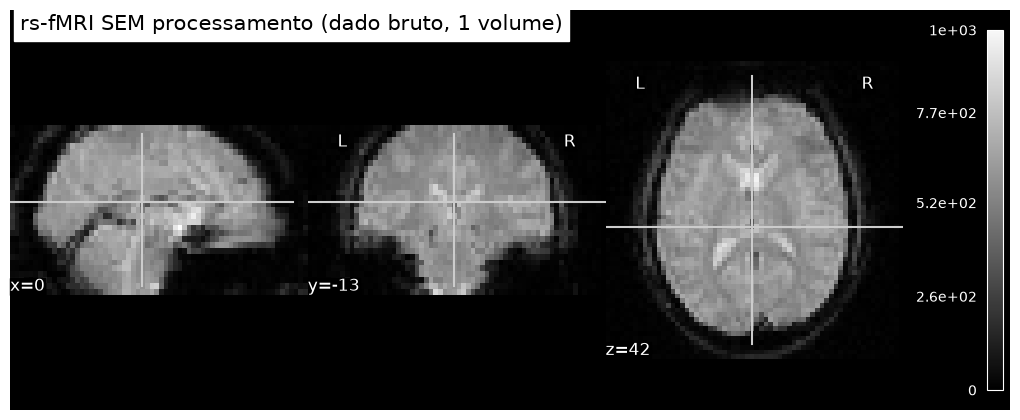

In [6]:
import matplotlib.pyplot as plt

# --------------------------------------------------------
# Figura 0 — rs-fMRI SEM processamento (dado bruto), para contraste
# didático com a Figura 1 (pré-processado), logo a seguir.
# --------------------------------------------------------
if os.path.exists(raw_path):
    raw_img = nib.load(raw_path)
    print('Dimensões do volume bruto:', raw_img.shape)

    # Se for 4D (série temporal completa), usamos só o primeiro volume
    # para a visualização estática dos cortes.
    raw_vol0 = index_img(raw_img, 0) if len(raw_img.shape) == 4 else raw_img

    fig = plt.figure(figsize=(10, 4))
    plotting.plot_epi(
        raw_vol0, display_mode='ortho',
        title='rs-fMRI SEM processamento (dado bruto, 1 volume)',
        figure=fig, cmap='gray',
    )
    plt.savefig(
        os.path.join(PATHS['figures'], '03_fig0_rsfmri_bruto.png'),
        dpi=300, bbox_inches='tight'
    )
    plt.show()
else:
    print('Célula pulada: arquivo bruto não disponível (ver instruções acima).')

#### Figura 1 — rs-fMRI pré-processado (cortes axial, sagital, coronal)

[fetch_abide_pcp] Dataset directory found: C:\Users\Maria Eduarda\Downloads\TCC_TEA_TDAH\Data\raw\ABIDE_pcp
[fetch_abide_pcp] Downloading data from https://s3.amazonaws.com/fcp-indi/data/Projects/ABIDE_Initiative/Outputs/cpac/filt_noglobal/func_mean/Pitt_0050003_func_mean.nii.gz ...
Downloaded 163840 of 520646 bytes (31.5%%, 00 HR 00 MIN 02 SEC remaining)
Downloaded 319488 of 520646 bytes (61.4%%, 00 HR 00 MIN 01 SEC remaining)
Downloaded 458752 of 520646 bytes (88.1%%, 00 HR 00 MIN 00 SEC remaining)
[fetch_abide_pcp]  ...done. (5 seconds, 0 min)



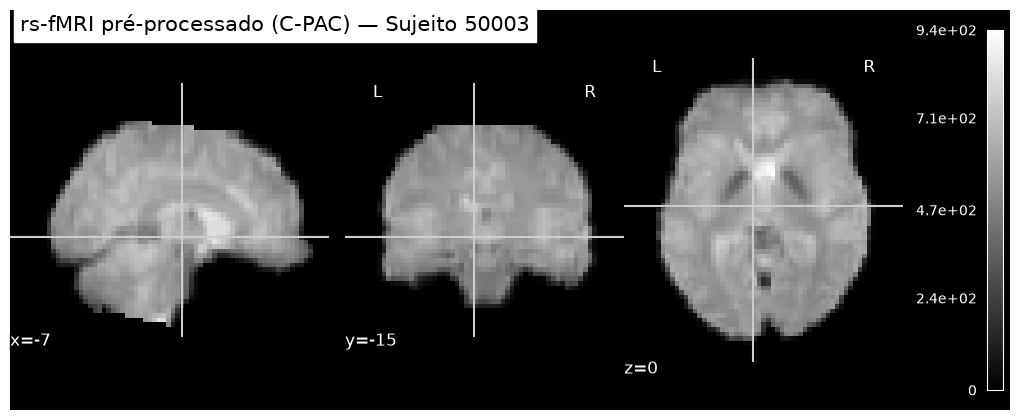


Compare com a Figura 0 (bruto): repare na ausência de crânio/tecidos
extracranianos, no alinhamento mais "padronizado" entre os cortes, e
no sinal visualmente menos ruidoso — efeitos diretos do pré-processamento.


In [7]:
from nilearn.datasets import fetch_abide_pcp
import matplotlib.pyplot as plt

# Baixa func_mean de apenas 1 sujeito — só para esta figura ilustrativa.
# Isso é independente do pipeline de classificação (que usa só rois_cc200).
abide_1sub = fetch_abide_pcp(
    data_dir=str(PATHS['raw']),
    n_subjects=1,
    pipeline="cpac",
    band_pass_filtering=True,
    global_signal_regression=False,
    derivatives=["func_mean"],
    quality_checked=True,
)

func_mean_img = abide_1sub.func_mean[0]
sub_id_exemplo = abide_1sub.phenotypic['SUB_ID'].iloc[0] # Alterado para usar .iloc[0]

fig = plt.figure(figsize=(10, 4))
plotting.plot_epi(
    func_mean_img,
    display_mode='ortho',
    title=f'rs-fMRI pré-processado (C-PAC) — Sujeito {sub_id_exemplo}',
    figure=fig,
    cmap='gray',
)
plt.savefig(
    os.path.join(PATHS['figures'], '03_fig1_rsfmri_preprocessado.png'),
    dpi=300, bbox_inches='tight'
)
plt.show()

print('\nCompare com a Figura 0 (bruto): repare na ausência de crânio/tecidos')
print('extracranianos, no alinhamento mais "padronizado" entre os cortes, e')
print('no sinal visualmente menos ruidoso — efeitos diretos do pré-processamento.')

#### Figura 2 — Atlas CC200 sobreposto ao cérebro

Atlas CC200 baixado em: C:\Users\Maria Eduarda\Downloads\TCC_TEA_TDAH\Data\raw\cc200_roi_atlas.nii.gz
Número de regiões detectadas no atlas: 200


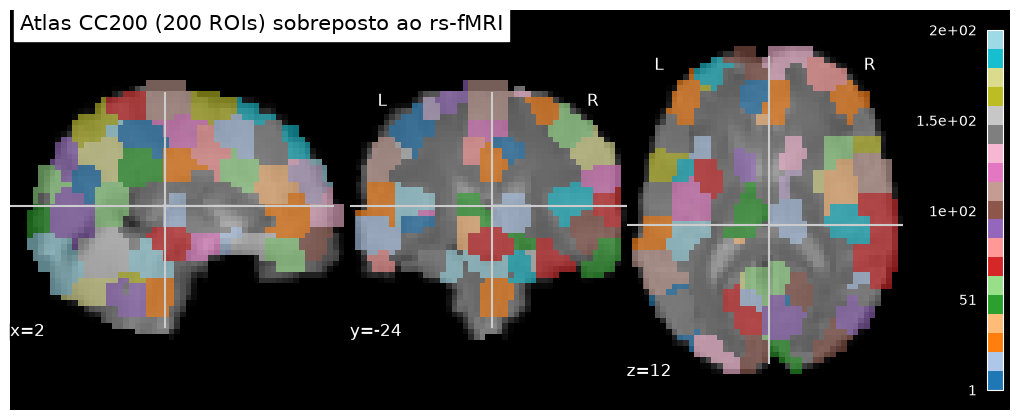

In [8]:
import urllib.request
import numpy as np # Adicionado para corrigir NameError

atlas_url = 'https://fcp-indi.s3.amazonaws.com/data/Projects/ABIDE_Initiative/Resources/cc200_roi_atlas.nii.gz'
atlas_path = os.path.join(PATHS['raw'], 'cc200_roi_atlas.nii.gz')

if not os.path.exists(atlas_path):
    urllib.request.urlretrieve(atlas_url, atlas_path)
    print('Atlas CC200 baixado em:', atlas_path)
else:
    print('Atlas já existe em:', atlas_path)

atlas_img = nib.load(atlas_path)
rotulos_unicos = np.unique(atlas_img.get_fdata())
n_regioes = len(rotulos_unicos) - 1  # subtrai o rótulo 0 (fundo)
print(f'Número de regiões detectadas no atlas: {n_regioes}')

fig = plt.figure(figsize=(10, 4))
plotting.plot_roi(
    atlas_img,
    bg_img=func_mean_img,
    display_mode='ortho',
    title=f'Atlas CC200 ({n_regioes} ROIs) sobreposto ao rs-fMRI',
    alpha=0.6,
    figure=fig,
    cmap='tab20',
)
plt.savefig(
    os.path.join(PATHS['figures'], '03_fig2_atlas_cc200.png'),
    dpi=300, bbox_inches='tight'
)
plt.show()

#### Figura 3 — Séries temporais BOLD de algumas ROIs

Sujeito 50003: 196 volumes de tempo, 200 ROIs


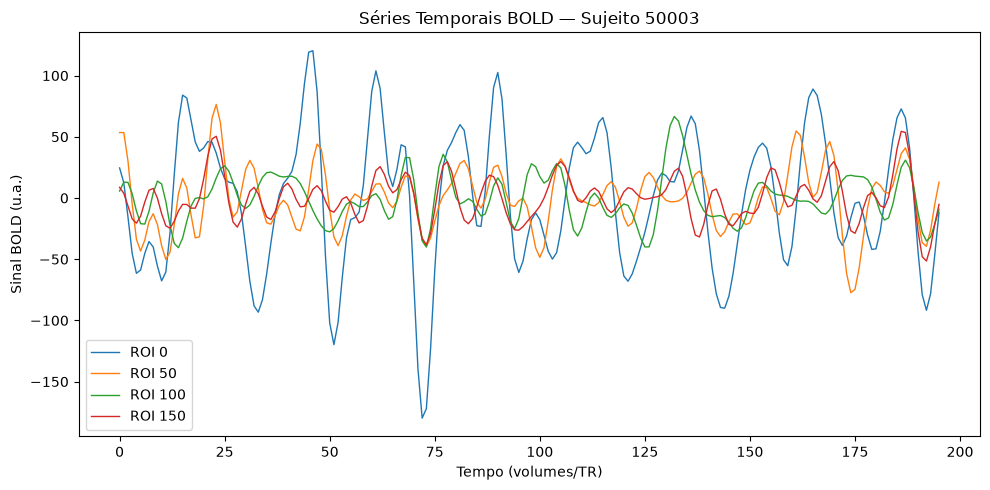

In [9]:
exigir_arquivo(PATHS['roi_timeseries'] / 'roi_timeseries_abide.pkl', '02_Download_ABIDE.ipynb')

import pickle

with open(os.path.join(PATHS['roi_timeseries'], 'roi_timeseries_abide.pkl'), 'rb') as f:
    roi_timeseries = pickle.load(f)

sub_id_serie = list(roi_timeseries.keys())[0]
serie = roi_timeseries[sub_id_serie]   # shape: [tempo, N_ROIs]

n_rois_sujeito = serie.shape[1]
print(f'Sujeito {sub_id_serie}: {serie.shape[0]} volumes de tempo, {n_rois_sujeito} ROIs')

rois_exemplo = [r for r in [0, 50, 100, 150] if r < n_rois_sujeito]

fig, ax = plt.subplots(figsize=(10, 5))
for roi_idx in rois_exemplo:
    ax.plot(serie[:, roi_idx], label=f'ROI {roi_idx}', linewidth=1)

ax.set_xlabel('Tempo (volumes/TR)')
ax.set_ylabel('Sinal BOLD (u.a.)')
ax.set_title(f'Séries Temporais BOLD — Sujeito {sub_id_serie}')
ax.legend()
plt.tight_layout()
plt.savefig(
    os.path.join(PATHS['figures'], '03_fig3_series_temporais.png'),
    dpi=300, bbox_inches='tight'
)
plt.show()

In [10]:
# --------------------------------------------------------
# Salva um resumo textual da exploração para consulta rápida (Docs/)
# --------------------------------------------------------
resumo = f'''Resumo da Exploração — ABIDE I
Total de sujeitos: {len(phenotypic)}
Sites: {phenotypic['SITE_ID'].nunique()}
Distribuição diagnóstico: {phenotypic['DX_GROUP'].value_counts().to_dict()}

Figuras geradas em Figures/:
- 03_fig0_rsfmri_bruto.png       (rs-fMRI sem processamento, se disponível)
- 03_fig1_rsfmri_preprocessado.png
- 03_fig2_atlas_cc200.png
- 03_fig3_series_temporais.png
'''
with open(os.path.join(PATHS['docs'], '03_resumo_exploracao.txt'), 'w') as f:
    f.write(resumo)

print(resumo)

Resumo da Exploração — ABIDE I
Total de sujeitos: 871
Sites: 20
Distribuição diagnóstico: {2: 468, 1: 403}

Figuras geradas em Figures/:
- 03_fig0_rsfmri_bruto.png       (rs-fMRI sem processamento, se disponível)
- 03_fig1_rsfmri_preprocessado.png
- 03_fig2_atlas_cc200.png
- 03_fig3_series_temporais.png

